# Project 1: Tiny Neural Network

This is my first project and attempt at building a neural network. It will be a very small neural network with two hidden neurons. It will be governed by the following equations:

$$z_1=W_1x+b_1, \hspace{5mm} h_1=\tanh(z_1), $$
$$ \hat{y} = W_2h_1 + b_2, \hspace{5mm} \mathcal{L}=\frac{1}{2}(\hat{y}-y)^2$$

We will start by building a forward pass.


In [38]:
import numpy as np

# Initialising starting values

x=np.array([[0.5]])
y=np.array([[0.8]])
W_1 = np.array([[0.5],[-0.6]])
b_1 = np.array([[0.1],[0.2]])
W_2 = np.array([[0.7, -0.3]])
b_2 = np.array([[0.05]])

(1, 2)


In [4]:
# Setting up functions

z_1 = W_1@x + b_1
h_1 = np.tanh(z_1)
yhat = W_2@h_1+b_2
# L = 0.5*(yhat-y)**2

print(z_1.shape)

print("The loss is "+str(L[0][0]))
# print("z_1 shape: " + str(z_1.shape) + ", h_1 shape: " + str(h_1.shape) + ", yhat shape: " + str(yhat.shape))

(2, 1)


NameError: name 'L' is not defined

# Building the backpropagation machine

For the sake of rigorously building a neural network with backpropagation, we will calculate the local derivatives by hand. It is a good exercise for a first neural network since these are very simple functions. 

We firstly define our residual as $r=\hat{y}-y$, so that we can rewrite our loss function in the convenient form:
$$ \mathcal{L} = \frac{1}{2}r^2 $$
Then for our backpropagation we will begin with the straightforward computation of the first layer, namely $\bar{r}$:
$$ \bar{r} = \frac{\partial\mathcal{L}}{\partial r} = r $$
Next, we compute $\bar{\hat{y}}$:
$$ \bar{\hat{y}} = \bar{r}\frac{\partial r}{\partial \hat{y}} = \bar{r}\cdot 1 = r $$

With this we can now compute $\bar{W}_2$:

$$\bar{W}_2 = \frac{\partial\mathcal{L}}{\partial W_2} = \frac{\partial\mathcal{L}}{\partial\hat{y}}\frac{\partial\hat{y}}{\partial W_2} = \bar{\hat{y}}\frac{\partial\hat{y}}{\partial W_2} $$
Giving:
$$ \bar{W}_2 = r h_1^T $$
By an almost identical computation one yields the following results:
$$ \bar{b}_2 = r, \hspace{5mm} \bar{h}_1 = W_2^Tr $$


In [5]:
# Defining the residual, simplified loss and the adjoints

r = yhat - y
L = 0.5*r**2

W_2adj = r@h_1.T
b_2adj = r
h_1adj = W_2.T@r

print("The value of W_2 adjoint is " + str(W_2adj[0]) + " with dimension " + str(W_2adj.shape))
print("The value of b_2 adjoint is " + str(b_2adj[0]) + " with dimension " + str(b_2adj.shape))
print("The value of h_1 adjoint is " + str(h_1adj) + " with dimension " + str(h_1adj.shape))

print(r[0][0])

The value of W_2 adjoint is [-0.16301994  0.04830277] with dimension (1, 2)
The value of b_2 adjoint is [-0.48463672] with dimension (1, 1)
The value of h_1 adjoint is [[-0.3392457 ]
 [ 0.14539102]] with dimension (2, 1)
-0.4846367205770808


The next step naturally is to continue the backpropagation to the next layer. This is the layer governed by the equation:
$$ h_1 = \tanh(z_1) $$
So we aim to calculate the adjoint:
$$ \bar{z}_1 = \bar{h}_1 \frac{\partial\mathcal{L}}{\partial z_1} = \bar{h}_1 (1-\tanh^2(z_1)) $$
Giving:
$$ \bar{z}_1 = W_2^Tr\odot(1-h_1^2) $$
where $\odot$ is the Hadamard product which simply means componentwise multiplication for vectors/matrices/tensors of the same size.

In [6]:
z_1adj = h_1adj * (1-h_1**2)

print("The value of z_1 adjoint is " +str(z_1adj) + "with dimension " + str(z_1adj.shape))

The value of z_1 adjoint is [[-0.30086056]
 [ 0.14394674]]with dimension (2, 1)


To finish the backwards pass we turn to the last layer:
$$ z_1 = W_1x + b_1 $$
Again two easy calculations yield the following;
$$ \bar{W}_1 = \bar{z}_1x^T = W_2^Tr\odot(1-h_1^2)x^T $$
$$ \bar{b}_1 = \bar{z}_1 = W_2^Tr\odot(1-h_1^2) $$ 

In [7]:
W_1adj = z_1adj@x.T
b_1adj = z_1adj

print("The value of W_1 adjoint is " +str(W_1adj) + "the value of b_1 adjoint is "+str(b_1adj))

The value of W_1 adjoint is [[-0.15043028]
 [ 0.07197337]]the value of b_1 adjoint is [[-0.30086056]
 [ 0.14394674]]


In [8]:
def loss_value(W_1, b_1, W_2, b_2, x, y):
    z1 = W_1@x+b_1
    h1 = np.tanh(z1)
    yhat = W_2@h1 + b_2
    L = 1/2 * (yhat-y)**2
    
    return L.item()

In [9]:
# Testing the gradients

e = 1.0e-5
W1new = W_1.copy()
W1new[0][0]+= e

# Forward finite difference:

ffd = (loss_value(W1new,b_1,W_2,b_2,x,y)-loss_value(W_1,b_1,W_2,b_2,x,y))/e

print("The finite-difference estimate is: "+str(ffd)+". Using backpropagation the value for the adjoint is " + str(W_1adj[0,0]))

print("Absolute error:", abs(ffd - W_1adj[0, 0]))

The finite-difference estimate is: -0.1504295450122095. Using backpropagation the value for the adjoint is -0.15043027975149187
Absolute error: 7.347392823597865e-07


In [10]:
# Central finite difference

W1neg = W_1.copy()
W1neg[0][0] += -e

W1pos = W_1.copy()
W1pos[0][0] += e

cfd = (loss_value(W1pos,b_1,W_2,b_2,x,y)-loss_value(W1neg,b_1,W_2,b_2,x,y))/(2*e)

print("Absolute error:", abs(cfd-W_1adj[0,0]))

Absolute error: 7.033262861000367e-14


In [11]:
# CFD for all 7 parameters

w1array = np.zeros_like(W_1)
b1array = np.zeros_like(b_1)
w2array = np.zeros_like(W_2)
b2array = np.zeros_like(b_2)

# Perturbing each components. Using np.ndindex avoids having to case bash for matrix dimensionality.
# Also prints absolute errors with adjoint values using the central finite difference function. Note the coordinates
# given are indexed starting at (0,0) as opposed to the usual mathematics convention of (1,1).

for i in np.ndindex(W_1.shape):
    param1 = W_1.copy()
    param2 = W_1.copy()
    param1[i] += e
    param2[i] += -e
    w1array[i] = (loss_value(param1,b_1,W_2,b_2,x,y)-loss_value(param2,b_1,W_2,b_2,x,y))/(2*e)
    print("Absolute error for " + str(i) + "th component of W_1 is: " + str(abs(w1array[i]-W_1adj[i])))

for i in np.ndindex(b_1.shape):
    param1 = b_1.copy()
    param2 = b_1.copy()
    param1[i] += e
    param2[i] += -e
    b1array[i] = (loss_value(W_1,param1,W_2,b_2,x,y)-loss_value(W_1,param2,W_2,b_2,x,y))/(2*e)
    print("Absolute error for " + str(i) + "th component of b_1 is: " + str(abs(b1array[i]-b_1adj[i])))
    
for i in np.ndindex(W_2.shape):
    param1 = W_2.copy()
    param2 = W_2.copy()
    param1[i] += e
    param2[i] += -e
    w2array[i] = (loss_value(W_1,b_1,param1,b_2,x,y)-loss_value(W_1,b_1,param2,b_2,x,y))/(2*e)
    print("Absolute error for " + str(i) + "th component of W_2 is: " + str(abs(w2array[i]-W_2adj[i])))

for i in np.ndindex(b_2.shape):
    param1 = b_2.copy()
    param2 = b_2.copy()
    param1[i] += e
    param2[i] += -e
    b2array[i] = (loss_value(W_1,b_1,W_2,param1,x,y)-loss_value(W_1,b_1,W_2,param2,x,y))/(2*e)
    print("Absolute error for " + str(i) + "th component of b_2 is: " + str(abs(b2array[i]-b_2adj[i])))





Absolute error for (0, 0)th component of W_1 is: 7.033262861000367e-14
Absolute error for (1, 0)th component of W_1 is: 2.974009927214638e-14
Absolute error for (0, 0)th component of b_1 is: 6.385669770736513e-12
Absolute error for (1, 0)th component of b_1 is: 4.22281654088863e-12
Absolute error for (0, 0)th component of W_2 is: 5.606071162844728e-13
Absolute error for (0, 1)th component of W_2 is: 1.807581861967833e-14
Absolute error for (0, 0)th component of b_2 is: 4.71733763163229e-13


# AD using PyTorch

This section connects the previous section by using the PyTorch library to perform AD rather than manually coding it.

In [12]:
import torch

In [13]:
# # Building our parameters as PyTorch tensors

# # Requires grad is initialised to true since we need to keep track of the gradients of these parameters
# W1t = torch.tensor(W_1, dtype=torch.float64, requires_grad=True)
# b1t = torch.tensor(b_1, dtype=torch.float64, requires_grad=True)
# W2t = torch.tensor(W_2, dtype=torch.float64, requires_grad=True)
# b2t = torch.tensor(b_2, dtype=torch.float64, requires_grad=True)
# # We treat these as constants and as such don't need to track the gradients
# xt = torch.tensor(x, dtype=torch.float64, requires_grad=False)
# yt = torch.tensor(y, dtype=torch.float64, requires_grad=False)

# # Rebuilding the forward pass
# z1t = W1t@xt + b1t
# h1t = torch.tanh(z1t)
# yhatt = W2t@h1t+b2t
# Lt = 1/2 * (yhatt-yt)**2

# print(Lt.item())

# Lt.backward()

In [14]:
# Lt.backward()

# print("W1 gradient tensor: " + str(W1t.grad))
# print("b1 gradient tensor: " + str(b1t.grad))
# print("W2 gradient tensor: " + str(W2t.grad))
# print("b2 gradient tensor: " + str(b2t.grad))

In [15]:
# eta = 0.1

# W1tnew = W1t-eta*W1t.grad
# b1tnew = b1t-eta*b1t.grad
# W2tnew = W2t-eta*W2t.grad
# b2tnew = b2t-eta*b2t.grad

# uploss = loss_value(W1tnew.detach().numpy(), b1tnew.detach().numpy(), W2tnew.detach().numpy(), 
#                     b2tnew.detach().numpy(), x, y)
# inloss = loss_value(W1t.detach().numpy(), b1t.detach().numpy(), W2t.detach().numpy(), 
#                     b2t.detach().numpy(), x, y)

# print("The updated loss is: " + str(uploss))
# print("The initial loss is: " + str(inloss))
# print("The change in the loss is: " + str(uploss - inloss))

In [24]:
def forward_pass(W1t, b1t, W2t, b2t, xt, yt):
    z1t = W1t@xt + b1t
    h1t = torch.tanh(z1t)
    yhatt = W2t@h1t+b2t
    Lt = 1/2 * (yhatt-yt)**2
    
    return Lt

In [27]:
# Rebuilding original parameters

# Requires grad is initialised to true since we need to keep track of the gradients of these parameters
W1t = torch.tensor(W_1, dtype=torch.float64, requires_grad=True)
b1t = torch.tensor(b_1, dtype=torch.float64, requires_grad=True)
W2t = torch.tensor(W_2, dtype=torch.float64, requires_grad=True)
b2t = torch.tensor(b_2, dtype=torch.float64, requires_grad=True)
# We treat these as constants and as such don't need to track the gradients
xt = torch.tensor(x, dtype=torch.float64, requires_grad=False)
yt = torch.tensor(y, dtype=torch.float64, requires_grad=False)

eta = 0.1
lossvalues = []

for i in range(100):
    # Clearing gradient values
    W1t.grad = None
    b1t.grad = None
    W2t.grad = None
    b2t.grad = None
    
    # Running forward pass and appending loss value to the list of loss values
    Lt = forward_pass(W1t, b1t, W2t, b2t, xt, yt)
    lossvalues.append(Lt.item())
    
    # Running the backwards pass
    Lt.backward()
    
    # Updates the four parameters
    with torch.no_grad():
        W1t -= eta*W1t.grad
        b1t -= eta*b1t.grad
        W2t -= eta*W2t.grad
        b2t -= eta*b2t.grad
        forward_pass(W1t, b1t, W2t, b2t, xt, yt)

print("Initial loss is: " + str(lossvalues[0]))
print("Final loss is: " + str(lossvalues[-1]))

Initial loss is: 0.11743637546585374
Final loss is: 1.6007353034786677e-19


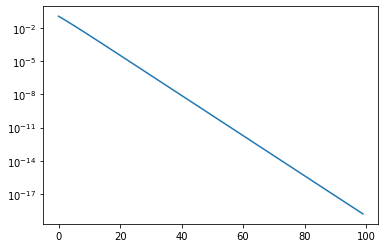

In [35]:
import matplotlib.pyplot as plt

plt.yscale('log')
plt.plot(lossvalues)